# Search Relevance Experiment Bench
**Project 07 | AI / ML Engineer | Search, language and knowledge tools**

**Note: this notebook is not directly shareable as a result. Open it in Google Colab, run all cells top to bottom (Runtime > Run all), and only then share the executed copy or the GitHub repo.**

### Problem
A small documentation site needs better search. Changing the ranking by gut feeling can make exact things (error codes, near-identical product names) harder to find. So I build an experiment bench: a judged query set, three retrievers and a report that shows where each one wins and loses.

### What I build
1. 100 fictional documentation pages (near-identical product names, exact error codes, pages with different wording for the same idea)
2. 40 queries with graded relevance (2 = best page, 1 = related page, 0 = not relevant). 8 queries have **no** right answer on purpose
3. A dev set (to tune) and a held-out set (only to report)
4. Three retrievers: BM25 keyword, LSA "semantic" (TF-IDF + SVD, runs fully offline) and a hybrid of the two
5. Metrics: recall@5, reciprocal rank (MRR) and no-answer handling, split by query type
6. A ranking difference report with regressions, not just wins
7. Acceptance tests (deterministic results, exact identifiers, deleted pages never shown)

### How to run
Run all cells. Everything is generated here (seed 42). No API key. Needs: numpy, pandas, scikit-learn, matplotlib.

In [1]:
!pip install -q numpy pandas scikit-learn matplotlib

## Step 1: Imports and config (versioned)

In [2]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

random.seed(42)
np.random.seed(42)

CONFIG = {"version": "v1", "bm25_k1": 1.5, "bm25_b": 0.75, "svd_dims": 12, "top_k": 5,
          "token_pattern": r"[a-z0-9]+(?:-[a-z0-9]+)*"}
print(CONFIG)

{'version': 'v1', 'bm25_k1': 1.5, 'bm25_b': 0.75, 'svd_dims': 12, 'top_k': 5, 'token_pattern': '[a-z0-9]+(?:-[a-z0-9]+)*'}


## Step 2: Make the 100 documentation pages
- 48 "target" pages: one per (product, topic). Each page uses only ONE way of saying the topic
- 18 "bridge" pages: general pages that use all the ways of saying a topic (this is what lets the semantic method learn that words mean the same)
- 25 error code pages (ERR-4001 ...)
- 9 release notes pages that mention two error codes each

In [3]:
products = ["Nimbus Gateway", "Nimbus Gateway Pro", "Nimbus Gateway Lite", "Nimbus Hub", "Nimbus Hub Mini",
            "Nimbus Sensor", "Nimbus Sensor X", "Nimbus Camera"]
concepts = {
    "reset": ["reset to factory settings", "restore the defaults", "wipe the configuration"],
    "pair": ["pair a new device", "link a new device", "connect a new device"],
    "firmware": ["update the firmware", "upgrade the firmware", "flash a newer version"],
    "offline": ["the device goes offline", "the connection is lost", "the network drops"],
    "slow": ["responses are slow", "there is high latency", "the dashboard feels laggy"],
    "battery": ["the battery drains fast", "the power cell runs out quickly", "the charge does not last"],
}
filler = ["Open the settings page first.", "Make sure the device is plugged in.", "Wait for the light to turn green.",
          "Contact support if nothing changes.", "This takes about five minutes.", "Keep a backup of your data."]

docs = []


def add_doc(kind, title, text, **extra):
    d = {"doc_id": "D" + str(len(docs) + 1).zfill(3), "kind": kind, "title": title, "text": text, "active": True}
    d.update(extra)
    docs.append(d)


# target pages
for p in products:
    for c, variants in concepts.items():
        v = random.choice(range(3))
        text = ("Guide for " + p + ". How to handle this: when " + variants[v] + ", follow these steps. " +
                " ".join(random.sample(filler, 3)))
        add_doc("target", p + " - " + c, text, product=p, concept=c, variant=v)

# bridge pages
for c, variants in concepts.items():
    for n in range(3):
        text = ("General Nimbus platform notes. People describe this problem in different ways: " + "; ".join(variants) +
                ". All of them mean the same task. " + random.choice(filler))
        add_doc("bridge", "Nimbus platform - " + c + " notes " + str(n + 1), text, concept=c)

# error code pages
codes = ["ERR-" + str(4000 + k * 7 + 1) for k in range(25)]
for code in codes:
    p = random.choice(products)
    c = random.choice(list(concepts.keys()))
    text = ("Error " + code + " on " + p + ". The device reports " + code + " when something goes wrong. " +
            "Check the cable, then try again. " + random.choice(filler))
    add_doc("error", "Error " + code, text, code=code, product=p)

# release notes
for n in range(9):
    two = random.sample(codes, 2)
    text = ("Release notes version 3." + str(n) + ". Fixed " + two[0] + " and " + two[1] + " on several Nimbus devices. " +
            "Minor improvements to the dashboard.")
    add_doc("release", "Release notes 3." + str(n), text, mentions=two)

corpus = pd.DataFrame(docs)
print(corpus.shape)
print(corpus["kind"].value_counts())
corpus[["doc_id", "kind", "title"]].head(8)

(100, 10)
kind
target     48
error      25
bridge     18
release     9
Name: count, dtype: int64


,doc_id,kind,title
0,D001,target,Nimbus Gateway - reset
1,D002,target,Nimbus Gateway - pair
2,D003,target,Nimbus Gateway - firmware
3,D004,target,Nimbus Gateway - offline
4,D005,target,Nimbus Gateway - slow
5,D006,target,Nimbus Gateway - battery
6,D007,target,Nimbus Gateway Pro - reset
7,D008,target,Nimbus Gateway Pro - pair


## Step 3: Make 40 judged queries
Each query keeps the right pages with a grade. Query types:
- **exact**: an error code (12)
- **name**: near-identical product names, like "Gateway" vs "Gateway Lite" (8)
- **paraphrase**: the query uses a different way of saying the topic than the target page (12)
- **noanswer**: nothing in the corpus answers it (8)

`split` = dev (used to choose the settings) or heldout (only to report).

In [4]:
queries = []


def add_query(qtype, text, grades):
    queries.append({"qid": "Q" + str(len(queries) + 1).zfill(2), "type": qtype, "query": text, "grades": grades})


by_title = {d["title"]: d for d in docs}

# exact id queries
for code in random.sample(codes, 12):
    grades = {}
    for d in docs:
        if d["kind"] == "error" and d["code"] == code:
            grades[d["doc_id"]] = 2
        if d["kind"] == "release" and code in d["mentions"]:
            grades[d["doc_id"]] = 1
    add_query("exact", code, grades)

# near-identical product names (same wording as the page)
for p in random.sample(products, 8):
    c = random.choice(list(concepts.keys()))
    d = by_title[p + " - " + c]
    phrase = concepts[c][d["variant"]]
    add_query("name", p + ": " + phrase, {d["doc_id"]: 2})

# paraphrase queries (a different wording than the page)
for p in random.sample(products, 8) + random.sample(products, 4):
    c = random.choice(list(concepts.keys()))
    d = by_title[p + " - " + c]
    other = [i for i in range(3) if i != d["variant"]]
    phrase = concepts[c][random.choice(other)]
    grades = {d["doc_id"]: 2}
    for b in docs:
        if b["kind"] == "bridge" and b["concept"] == c:
            grades[b["doc_id"]] = 1
    add_query("paraphrase", p + ": " + phrase, grades)

# no answer queries
for t in ["Nimbus Quantum Router warranty claim", "export invoices to accounting software", "Nimbus Drone propeller replacement",
          "how to change the billing currency", "Nimbus Speaker bluetooth codec", "voice assistant language packs",
          "solar panel mounting bracket", "student discount program"]:
    add_query("noanswer", t, {})

random.shuffle(queries)
for i, q in enumerate(queries):
    q["qid"] = "Q" + str(i + 1).zfill(2)

# held-out: 3 exact, 2 name, 4 paraphrase, 3 noanswer
held_counts = {"exact": 3, "name": 2, "paraphrase": 4, "noanswer": 3}
seen_counts = {"exact": 0, "name": 0, "paraphrase": 0, "noanswer": 0}
for q in queries:
    t = q["type"]
    if seen_counts[t] < held_counts[t]:
        q["split"] = "heldout"
        seen_counts[t] += 1
    else:
        q["split"] = "dev"

qdf = pd.DataFrame(queries)
print(qdf.groupby(["split", "type"]).size().unstack(fill_value=0))
qdf[["qid", "type", "split", "query"]].head(8)

type     exact  name  noanswer  paraphrase
split                                     
dev          9     6         5           8
heldout      3     2         3           4


,qid,type,split,query
0,Q01,paraphrase,heldout,Nimbus Hub: link a new device
1,Q02,exact,heldout,ERR-4113
2,Q03,noanswer,heldout,Nimbus Speaker bluetooth codec
3,Q04,noanswer,heldout,student discount program
4,Q05,exact,heldout,ERR-4022
5,Q06,paraphrase,heldout,Nimbus Camera: the battery drains fast
6,Q07,name,heldout,Nimbus Hub: the network drops
7,Q08,paraphrase,heldout,Nimbus Hub Mini: responses are slow


## Step 4: The three retrievers
1. **BM25** keyword. Tokens keep hyphens, so `ERR-4021` stays one exact token
2. **LSA** (TF-IDF then SVD to 12 dims). This is the offline stand-in for a vector search
3. **Hybrid** = alpha x BM25 + (1 - alpha) x LSA, each min-max scaled per query

In [5]:
doc_ids = list(corpus["doc_id"])
texts = list(corpus["text"].str.lower() + " " + corpus["title"].str.lower())

# BM25
cv = CountVectorizer(token_pattern=CONFIG["token_pattern"], lowercase=True, stop_words="english")
tf = cv.fit_transform(texts).toarray().astype(float)
n_docs = tf.shape[0]
df_t = (tf > 0).sum(axis=0)
idf = np.log(1 + (n_docs - df_t + 0.5) / (df_t + 0.5))
doc_len = tf.sum(axis=1)
avg_len = doc_len.mean()


def bm25_scores(q):
    qv = cv.transform([q.lower()]).toarray()[0]
    k1, b = CONFIG["bm25_k1"], CONFIG["bm25_b"]
    denom = tf + k1 * (1 - b + b * (doc_len / avg_len))[:, None]
    part = (tf * (k1 + 1)) / denom
    return (part * idf * (qv > 0)).sum(axis=1)


# LSA
tfidf = TfidfVectorizer(token_pattern=CONFIG["token_pattern"], sublinear_tf=True, stop_words="english")
X = tfidf.fit_transform(texts)
svd = TruncatedSVD(n_components=CONFIG["svd_dims"], random_state=42)
Z = svd.fit_transform(X)


def lsa_scores(q):
    qz = svd.transform(tfidf.transform([q.lower()]))
    return cosine_similarity(qz, Z)[0]


def minmax(a):
    return (a - a.min()) / (a.max() - a.min() + 1e-9)


def hybrid_scores(q, alpha):
    return alpha * minmax(bm25_scores(q)) + (1 - alpha) * minmax(lsa_scores(q))


print("docs:", n_docs, "| vocab:", tf.shape[1], "| svd explained variance:", round(svd.explained_variance_ratio_.sum(), 2))

docs: 100 | vocab: 123 | svd explained variance: 0.61


## Step 5: Metrics
- **recall@5**: share of the relevant pages (grade 1 or 2) found in the top 5
- **MRR**: 1 / rank of the first relevant page (0 if none in the top 5 pages)
- **no-answer**: the retriever should return nothing. It abstains when the top raw score is under a threshold chosen on dev only
All numbers are reported per query, so a good average can not hide a bad exact lookup.

In [6]:
K = CONFIG["top_k"]


def ranking(scores, active_only=True):
    order = np.argsort(-scores, kind="stable")
    out = []
    for i in order:
        if active_only and not corpus.loc[i, "active"]:
            continue
        out.append(doc_ids[i])
    return out


def metrics_for(ranked, grades):
    rel = [d for d, g in grades.items() if g >= 1]
    top = ranked[:K]
    rec = len(set(top) & set(rel)) / len(rel) if len(rel) > 0 else None
    rr = 0.0
    for pos, d in enumerate(top):
        if d in rel:
            rr = 1.0 / (pos + 1)
            break
    return rec, rr


# raw top scores for the abstain decision
bm25_ref = max(bm25_scores(q["query"]).max() for q in queries if q["split"] == "dev" and q["type"] != "noanswer")


def raw_top(name, q, alpha=None):
    if name == "keyword":
        return bm25_scores(q).max() / bm25_ref
    if name == "semantic":
        return lsa_scores(q).max()
    return alpha * (bm25_scores(q).max() / bm25_ref) + (1 - alpha) * lsa_scores(q).max()


def get_scores(name, q, alpha=None):
    if name == "keyword":
        return bm25_scores(q)
    if name == "semantic":
        return lsa_scores(q)
    return hybrid_scores(q, alpha)


def evaluate(name, alpha=None, split=None, thr=None):
    rows = []
    for q in queries:
        if split and q["split"] != split:
            continue
        sc = get_scores(name, q["query"], alpha)
        ranked = ranking(sc)
        if q["type"] == "noanswer":
            top_raw = raw_top(name, q["query"], alpha)
            abstained = (thr is not None) and (top_raw < thr)
            rows.append({"qid": q["qid"], "type": q["type"], "split": q["split"], "recall": None, "mrr": None,
                         "abstained": abstained, "top_raw": top_raw})
        else:
            rec, rr = metrics_for(ranked, q["grades"])
            rows.append({"qid": q["qid"], "type": q["type"], "split": q["split"], "recall": rec, "mrr": rr,
                         "abstained": None, "top_raw": raw_top(name, q["query"], alpha)})
    return pd.DataFrame(rows)


print("bm25 reference score (dev):", round(bm25_ref, 2))

bm25 reference score (dev): 11.94


## Step 6: Choose alpha and the abstain threshold on dev only
The alpha table also shows exact-id MRR for each alpha. If an alpha helps paraphrases but hurts exact lookup, I should see it here.

In [7]:
alpha_rows = []
for a in [0.0, 0.25, 0.5, 0.75, 1.0]:
    ev = evaluate("hybrid", alpha=a, split="dev")
    ans = ev[ev["type"] != "noanswer"]
    alpha_rows.append({"alpha": a, "dev_MRR": round(ans["mrr"].mean(), 3),
                       "exact_MRR": round(ans[ans["type"] == "exact"]["mrr"].mean(), 3),
                       "name_MRR": round(ans[ans["type"] == "name"]["mrr"].mean(), 3),
                       "paraphrase_MRR": round(ans[ans["type"] == "paraphrase"]["mrr"].mean(), 3)})
alpha_df = pd.DataFrame(alpha_rows)
print(alpha_df.to_string(index=False))

# rule: exact-id MRR must not drop below the keyword-only value, then take the best dev MRR (tie goes to bigger alpha)
keyword_exact = float(alpha_df[alpha_df["alpha"] == 1.0]["exact_MRR"].iloc[0])
safe = alpha_df[alpha_df["exact_MRR"] >= keyword_exact - 1e-9]
print("alphas that keep exact lookup as good as keyword:", list(safe["alpha"]))
best = safe.sort_values(["dev_MRR", "alpha"], ascending=[False, False]).iloc[0]
ALPHA = float(best["alpha"])
CONFIG["alpha"] = ALPHA
print("chosen alpha:", ALPHA)


def pick_threshold(name):
    ev = evaluate(name, alpha=ALPHA, split="dev")
    ans = ev[ev["type"] != "noanswer"]["top_raw"].values
    noa = ev[ev["type"] == "noanswer"]["top_raw"].values
    best_t, best_score = 0, -1
    for t in sorted(set(list(ans) + list(noa))):
        # correct decisions: answerable queries above t, noanswer queries below t
        score = (ans >= t).sum() + (noa < t).sum()
        if score > best_score:
            best_score = score
            best_t = t
    return best_t


THR = {n: pick_threshold(n) for n in ["keyword", "semantic", "hybrid"]}
CONFIG["thresholds"] = {k: round(float(v), 3) for k, v in THR.items()}
print("abstain thresholds (dev):", CONFIG["thresholds"])

 alpha  dev_MRR  exact_MRR  name_MRR  paraphrase_MRR
  0.00    0.870      0.889       1.0           0.750
  0.25    0.884      1.000       1.0           0.667
  0.50    0.877      1.000       1.0           0.646
  0.75    0.804      1.000       1.0           0.438
  1.00    0.773      1.000       1.0           0.348
alphas that keep exact lookup as good as keyword: [0.25, 0.5, 0.75, 1.0]
chosen alpha: 0.25
abstain thresholds (dev): {'keyword': 0.45, 'semantic': 0.771, 'hybrid': 0.712}


## Step 7: Compare the three retrievers (dev and held-out separately)

retriever   split  recall@5   MRR  exact_MRR  name_MRR  paraphrase_MRR noanswer_correct
  keyword     dev     0.837 0.773      1.000      1.00           0.348              1/5
  keyword heldout     0.778 0.704      1.000      0.75           0.458              1/3
 semantic     dev     0.768 0.870      0.889      1.00           0.750              1/5
 semantic heldout     0.694 0.889      1.000      0.75           0.875              1/3
   hybrid     dev     0.859 0.884      1.000      1.00           0.667              1/5
   hybrid heldout     0.778 0.889      1.000      0.75           0.875              1/3


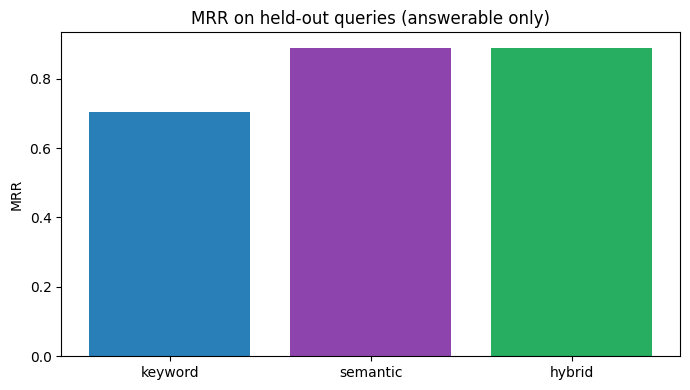

In [8]:
summary = []
all_eval = {}
for name in ["keyword", "semantic", "hybrid"]:
    ev = evaluate(name, alpha=ALPHA, thr=THR[name])
    all_eval[name] = ev
    for sp in ["dev", "heldout"]:
        part = ev[ev["split"] == sp]
        ans = part[part["type"] != "noanswer"]
        noa = part[part["type"] == "noanswer"]
        summary.append({"retriever": name, "split": sp, "recall@5": round(ans["recall"].mean(), 3), "MRR": round(ans["mrr"].mean(), 3),
                        "exact_MRR": round(ans[ans["type"] == "exact"]["mrr"].mean(), 3),
                        "name_MRR": round(ans[ans["type"] == "name"]["mrr"].mean(), 3),
                        "paraphrase_MRR": round(ans[ans["type"] == "paraphrase"]["mrr"].mean(), 3),
                        "noanswer_correct": str(int(noa["abstained"].sum())) + "/" + str(len(noa))})
sum_df = pd.DataFrame(summary)
print(sum_df.to_string(index=False))

held = sum_df[sum_df["split"] == "heldout"]
plt.figure(figsize=(7, 4))
plt.bar(held["retriever"], held["MRR"], color=["#2980b9", "#8e44ad", "#27ae60"])
plt.title("MRR on held-out queries (answerable only)")
plt.ylabel("MRR")
plt.tight_layout()
plt.savefig("heldout_mrr.png")
plt.show()

## Step 8: Ranking difference report
For each answerable query I compare the rank of the first relevant page in keyword search and in the hybrid. Moves are shown both ways, including the regressions (where hybrid is worse).

In [9]:
def first_rel_rank(name, q):
    ranked = ranking(get_scores(name, q["query"], ALPHA))
    rel = [d for d, g in q["grades"].items() if g >= 1]
    for pos, d in enumerate(ranked):
        if d in rel:
            return pos + 1
    return 999


move_rows = []
for q in queries:
    if q["type"] == "noanswer":
        continue
    rk = first_rel_rank("keyword", q)
    rh = first_rel_rank("hybrid", q)
    move_rows.append({"qid": q["qid"], "type": q["type"], "split": q["split"], "query": q["query"], "keyword_rank": rk, "hybrid_rank": rh, "moved": rk - rh})
mv = pd.DataFrame(move_rows)

print("improved:", int((mv["moved"] > 0).sum()), "| same:", int((mv["moved"] == 0).sum()), "| regressed:", int((mv["moved"] < 0).sum()))
print()
print("TOP WINS (hybrid better):")
print(mv.sort_values("moved", ascending=False).head(3)[["qid", "type", "query", "keyword_rank", "hybrid_rank"]].to_string(index=False))
print()
print("TOP REGRESSIONS (hybrid worse):")
reg = mv.sort_values("moved").head(3)
reg = reg[reg["moved"] < 0]
if len(reg) == 0:
    print("none on this run, check exact-id rows above anyway")
else:
    print(reg[["qid", "type", "query", "keyword_rank", "hybrid_rank"]].to_string(index=False))
mv.to_csv("ranking_differences.csv", index=False)

improved: 9 | same: 23 | regressed: 0

TOP WINS (hybrid better):
qid       type                                         query  keyword_rank  hybrid_rank
Q06 paraphrase        Nimbus Camera: the battery drains fast             6            1
Q25 paraphrase Nimbus Gateway Lite: the charge does not last             6            2
Q37 paraphrase        Nimbus Sensor X: flash a newer version             5            2

TOP REGRESSIONS (hybrid worse):
none on this run, check exact-id rows above anyway


In [10]:
# what was the change I did NOT keep? pure semantic search (alpha = 0) on exact identifiers
sem_exact = evaluate("semantic", split=None)
sem_ans = sem_exact[(sem_exact["type"] == "exact")]
key_exact = all_eval["keyword"][all_eval["keyword"]["type"] == "exact"]
print("exact-id MRR  keyword:", round(key_exact["mrr"].mean(), 3), "| semantic only:", round(sem_ans["mrr"].mean(), 3))
print("pure semantic search is rejected as the default if its exact-id MRR is lower than keyword.")

exact-id MRR  keyword: 1.0 | semantic only: 0.917
pure semantic search is rejected as the default if its exact-id MRR is lower than keyword.


## Step 9: Acceptance tests

In [11]:
# test 1: deterministic retrievers give the same rankings every time
def all_rankings(name):
    return [ranking(get_scores(name, q["query"], ALPHA)) for q in queries]


same = all_rankings("keyword") == all_rankings("keyword") and all_rankings("hybrid") == all_rankings("hybrid")
print("TEST 1 same corpus + config -> same rankings:", "PASS" if same else "FAIL")

# test 2: exact identifier queries are tested on their own, per retriever
for name in ["keyword", "semantic", "hybrid"]:
    ex = all_eval[name][all_eval[name]["type"] == "exact"]
    print("TEST 2", name, "exact id MRR:", round(ex["mrr"].mean(), 3), "| queries with rr = 0:", int((ex["mrr"] == 0).sum()))

# test 3: deleted pages never show up, even if a cached ranking still has the id
cached = {q["qid"]: ranking(get_scores("hybrid", q["query"], ALPHA), active_only=False)[:K] for q in queries}
to_delete = []
for q in queries[:6]:
    if len(cached[q["qid"]]) > 0:
        to_delete.append(cached[q["qid"]][0])
to_delete = list(set(to_delete))[:3]
for d in to_delete:
    corpus.loc[corpus["doc_id"] == d, "active"] = False
print("deleted pages:", to_delete)


def snippet(doc_id):
    row = corpus[corpus["doc_id"] == doc_id].iloc[0]
    if not row["active"]:
        return None
    return row["text"][:70]


leak_cache = 0
for qid, lst in cached.items():
    for d in lst:
        if d in to_delete and snippet(d) is not None:
            leak_cache += 1
fresh = 0
for q in queries:
    for d in ranking(get_scores("hybrid", q["query"], ALPHA))[:K]:
        if d in to_delete:
            fresh += 1
print("TEST 3 snippets shown from cached rankings for deleted pages:", leak_cache, "| deleted pages in fresh results:", fresh, "->", "PASS" if leak_cache == 0 and fresh == 0 else "FAIL")

TEST 1 same corpus + config -> same rankings: PASS
TEST 2 keyword exact id MRR: 1.0 | queries with rr = 0: 0
TEST 2 semantic exact id MRR: 0.917 | queries with rr = 0: 0
TEST 2 hybrid exact id MRR: 1.0 | queries with rr = 0: 0
deleted pages: ['D092', 'D020', 'D070']
TEST 3 snippets shown from cached rankings for deleted pages: 0 | deleted pages in fresh results: 0 -> PASS


## Step 10: Key insights
1. Look at the exact-id column first. Keyword search should be near perfect there. If the semantic only method is lower, that is the reason it can not be the default.
2. Paraphrase queries are where the semantic part is supposed to help. Check if hybrid really moved those up, and by how much.
3. The regression list is as important as the wins. A hybrid is only worth the extra work if it helps without breaking exact lookup.
4. No-answer queries are handled by a score threshold picked on dev. Check the held-out count, because a threshold chosen on 5 queries can easily be wrong.
5. The semantic part here is LSA on a tiny made-up corpus. It shows the method, but real embeddings and real queries could behave differently.

---
**Built by Akshat Kesharwani**  |  Portfolio: https://akshatkesharwani-info.github.io/  |  GitHub: https://github.com/akshatkesharwani-info

Idea source: "Top 50 Projects to Build in 2026" (Yasir Arafat Sharfi). The build, data and code here are my own.